# 03. Modelagem de Regressão Linear, Validação Temporal e Diagnóstico

**Etapa CRISP-DM:** Modelagem e Avaliação (*MLOps Benchmark & Diagnostics*)

### Metodologia de Validação (sem Data Leakage)
- **Conjunto de Treino**: `2024-02` até `2026-06` (seleção de hiperparâmetros com *Expanding-Window* `TimeSeriesSplit`).
- **Conjunto de Validação Out-of-Time (Holdout 2026)**: últimos 4 meses fechados (`2026-07` a `2026-10`).
- **Modelos comparados (família Regressão Linear)**: `OLS`, `Ridge`, `Lasso`, `ElasticNet` e `HuberRegressor`, testando tanto a formulação **Taxa por Dia Útil Ponderado** (`y / DU * DU`) quanto **Volume Direto** (`dias_uteis_ponderados` como preditor), além do impacto explícito de tratar as anomalias de baixa em lote nas retiradas.
- Após escolher os campeões pelo erro fora da amostra, cada campeão é **re-treinado com 100% dos meses fechados** para gerar a projeção de 2027.

In [1]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path("..").resolve()
DATA_PROC = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "reports" / "figures"

sns.set_theme(style="whitegrid")

with open(MODELS_DIR / "metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

bench_v = pd.read_csv(MODELS_DIR / "benchmark_vendas.csv")
bench_r = pd.read_csv(MODELS_DIR / "benchmark_retiradas.csv")
df_ml = pd.read_parquet(DATA_PROC / "serie_mensal_ml.parquet")
df_closed = df_ml[df_ml["mes_fechado"]].copy()

print("=== BENCHMARK DE MODELOS LINEARES — VENDAS ===")
display(bench_v)

print("=== BENCHMARK DE MODELOS LINEARES — RETIRADAS ===")
display(bench_r)


=== BENCHMARK DE MODELOS LINEARES — VENDAS ===


,modelo,config,usa_taxa_du,cv_rmse,cv_mape_pct,val_mae,val_rmse,val_mape_pct,val_r2,score
0,ElasticNet_Taxa_DU,"ElasticNet(a=0.5,l1=0.8)",True,151.03,11.77,50.92,58.84,2.55,0.2479,4.856
1,Ridge_Taxa_DU,Ridge(alpha=5.0),True,155.22,11.78,56.35,74.88,2.77,-0.2177,5.022
2,ElasticNet_Direto,"ElasticNet(a=0.5,l1=0.8)",False,116.86,10.12,67.68,74.17,3.39,-0.1948,5.072
3,Lasso_Taxa_DU,Lasso(alpha=0.5),True,167.34,12.86,67.52,74.30,3.44,-0.1991,5.794
4,Ridge_Direto,Ridge(alpha=1.0),False,124.76,10.61,86.47,95.55,4.41,-0.9829,5.960
5,Lasso_Direto,Lasso(alpha=5.0),False,128.05,10.13,104.07,118.11,5.31,-2.0296,6.514
6,OLS_Direto,OLS,False,187.37,17.04,112.80,132.03,5.77,-2.7861,8.589
7,OLS_Taxa_DU,OLS,True,248.47,24.27,102.61,118.89,5.24,-2.0700,9.996


=== BENCHMARK DE MODELOS LINEARES — RETIRADAS ===


,modelo,config,usa_taxa_du,cv_rmse,cv_mape_pct,val_mae,val_rmse,val_mape_pct,val_r2,score
0,ElasticNet_Direto_Limpo,"ElasticNet(a=0.1,l1=0.5)",False,104.62,29.88,33.29,40.91,3.42,0.4196,10.036
1,Ridge_Taxa_DU_Limpo,Ridge(alpha=0.5),True,106.39,25.00,50.38,52.22,5.29,0.0543,10.217
2,ElasticNet_Taxa_DU_Limpo,"ElasticNet(a=0.1,l1=0.2)",True,108.79,27.69,52.63,56.68,5.49,-0.1143,11.041
3,Huber_Taxa_DU_ComAnomalias,"Huber(eps=1.6,a=1.0)",True,265.64,30.51,46.59,49.31,4.96,0.1568,11.347
4,Ridge_Direto_Limpo,Ridge(alpha=5.0),False,105.74,28.62,63.44,67.98,6.57,-0.6029,12.082
5,Lasso_Taxa_DU_Limpo,Lasso(alpha=0.05),True,116.24,29.91,63.36,65.46,6.54,-0.4864,12.383
6,OLS_Taxa_DU_Limpo,OLS,True,148.77,36.49,60.74,61.74,6.30,-0.3219,13.848
7,Lasso_Direto_Limpo,Lasso(alpha=10.0),False,125.69,35.79,74.88,78.77,7.81,-1.1520,14.806
8,OLS_Direto_Limpo,OLS,False,180.60,55.43,37.90,44.27,3.87,0.3203,16.759
9,OLS_Direto_SemTratarAnomalias,OLS,False,548.42,73.54,87.51,89.12,9.19,-1.7545,25.277


## 1. Desempenho no Holdout Out-of-Time (Jul/2026 a Out/2026)

A tabela e os gráficos abaixo comparam o **Valor Real vs. Valor Previsto** pelos modelos campeões nos 4 meses de holdout que ficaram totalmente ocultos durante o treinamento.

Campeão VENDAS: ElasticNet_Taxa_DU | ElasticNet(a=0.5,l1=0.8)
Métricas Holdout 2026: {'MAE': 50.92, 'RMSE': 58.84, 'MAPE_pct': 2.55, 'R2': 0.2479, 'Bias': -11.88}


,anomes,real,previsto,erro,erro_pct
0,2026-07,2084.0,2058.40,-25.60,-1.23
1,2026-08,2031.0,1930.99,-100.01,-4.92
2,2026-09,1935.0,1982.56,47.56,2.46
3,2026-10,1920.0,1950.51,30.51,1.59



Campeão RETIRADAS: ElasticNet_Direto_Limpo | ElasticNet(a=0.1,l1=0.5)
Métricas Holdout 2026: {'MAE': 33.29, 'RMSE': 40.91, 'MAPE_pct': 3.42, 'R2': 0.4196, 'Bias': -33.29}


,anomes,real,previsto,erro,erro_pct
0,2026-07,866.0,856.87,-9.13,-1.05
1,2026-08,974.0,902.81,-71.19,-7.31
2,2026-09,995.0,960.07,-34.93,-3.51
3,2026-10,996.0,978.08,-17.92,-1.80


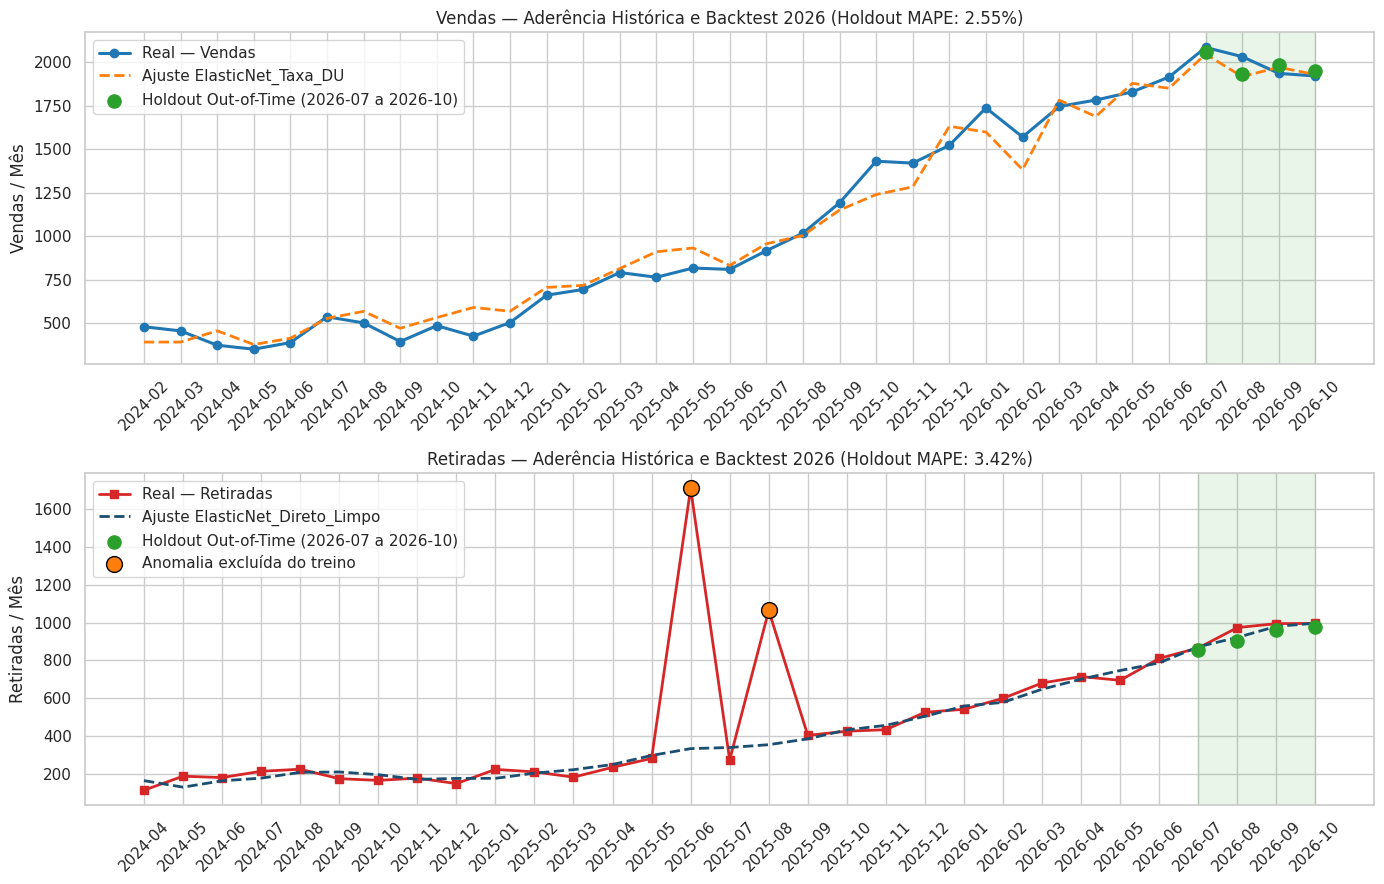

In [2]:
val_v = pd.DataFrame(meta["champion_vendas"]["val_predictions"])
val_r = pd.DataFrame(meta["champion_retiradas"]["val_predictions"])

print(f"Campeão VENDAS: {meta['champion_vendas']['model_name']} | {meta['champion_vendas']['best_config']}")
print("Métricas Holdout 2026:", meta["champion_vendas"]["val_metrics"])
display(val_v)

print(f"\nCampeão RETIRADAS: {meta['champion_retiradas']['model_name']} | {meta['champion_retiradas']['best_config']}")
print("Métricas Holdout 2026:", meta["champion_retiradas"]["val_metrics"])
display(val_r)

# Carregar artefatos finais para visualizar ajuste completo + holdout
art_v = joblib.load(MODELS_DIR / "modelo_vendas.joblib")
art_r = joblib.load(MODELS_DIR / "modelo_retiradas.joblib")

df_v_plot = df_closed.dropna(subset=art_v["features"]).copy()
pred_v_raw = art_v["pipeline"].predict(df_v_plot[art_v["features"]])
df_v_plot["vendas_fit"] = pred_v_raw * df_v_plot["dias_uteis_ponderados"] if art_v["scale_by_du"] else pred_v_raw

df_r_plot = df_closed.dropna(subset=art_r["features"]).copy()
pred_r_raw = art_r["pipeline"].predict(df_r_plot[art_r["features"]])
df_r_plot["retiradas_fit"] = pred_r_raw * df_r_plot["dias_uteis_ponderados"] if art_r["scale_by_du"] else pred_r_raw

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)

# Vendas
axes[0].plot(df_v_plot["anomes"], df_v_plot["vendas"], marker="o", lw=2.2, label="Real — Vendas", color="#1f77b4")
axes[0].plot(df_v_plot["anomes"], df_v_plot["vendas_fit"], ls="--", lw=2.0, label=f"Ajuste {art_v['model_name']}", color="#ff7f0e")
axes[0].scatter(val_v["anomes"], val_v["previsto"], s=90, color="#2ca02c", zorder=5, label="Holdout Out-of-Time (2026-07 a 2026-10)")
axes[0].axvspan("2026-07", "2026-10", color="#2ca02c", alpha=0.10)
axes[0].set_title(f"Vendas — Aderência Histórica e Backtest 2026 (Holdout MAPE: {meta['champion_vendas']['val_metrics']['MAPE_pct']}%)")
axes[0].set_ylabel("Vendas / Mês")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(loc="upper left")

# Retiradas
axes[1].plot(df_r_plot["anomes"], df_r_plot["retiradas"], marker="s", lw=2.0, label="Real — Retiradas", color="#d62728")
axes[1].plot(df_r_plot["anomes"], df_r_plot["retiradas_fit"], ls="--", lw=2.0, label=f"Ajuste {art_r['model_name']}", color="#1b4f72")
axes[1].scatter(val_r["anomes"], val_r["previsto"], s=90, color="#2ca02c", zorder=5, label="Holdout Out-of-Time (2026-07 a 2026-10)")
anom_r = df_r_plot[df_r_plot["anomalia_retirada"] == 1]
axes[1].scatter(anom_r["anomes"], anom_r["retiradas"], s=130, color="#ff7f0e", edgecolor="black", zorder=6, label="Anomalia excluída do treino")
axes[1].axvspan("2026-07", "2026-10", color="#2ca02c", alpha=0.10)
axes[1].set_title(f"Retiradas — Aderência Histórica e Backtest 2026 (Holdout MAPE: {meta['champion_retiradas']['val_metrics']['MAPE_pct']}%)")
axes[1].set_ylabel("Retiradas / Mês")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_backtest_vendas_e_retiradas.png", dpi=140)
plt.show()


## 2. Interpretação dos Coeficientes e Diagnóstico Estatístico dos Resíduos

Uma das maiores vantagens da Regressão Linear é a **interpretabilidade executiva**: conseguimos inspecionar exatamente o peso de cada variável (tanto padronizada para importância relativa quanto na escala original para interpretação de negócio) e validar as premissas clássicas nos resíduos (normalidade via **Shapiro-Wilk** e autocorrelação via **Durbin-Watson**).

=== COEFICIENTES — MODELO CAMPEÃO DE VENDAS ===


,feature,coef_scaled,coef_original
0,qtd_bairros_ativos_mes,9.326007,0.130585
1,qtd_canais_ativos_mes,3.964042,2.298157
2,vendas_por_du_lag1,11.515862,0.453794
3,mes_sin,0.000000,0.000000
4,mes_cos,1.309034,1.924128


Diagnóstico de Resíduos (Vendas): {'n_obs': 33, 'residual_mean': -0.745, 'residual_std': 90.055, 'durbin_watson': 1.409, 'shapiro_stat': 0.9596, 'shapiro_pvalue': 0.2516}

=== COEFICIENTES — MODELO CAMPEÃO DE RETIRADAS ===


,feature,coef_scaled,coef_original
0,dias_uteis_ponderados,6.717230,5.702336
1,carteira_inicio_mes,97.782543,0.017445
2,vendas_acum_3m_ant,92.535245,0.052741
3,retiradas_lag1,87.245740,0.327315
4,mes_sin,-13.094590,-18.228252
5,mes_cos,-7.465684,-10.784874


Diagnóstico de Resíduos (Retiradas): {'n_obs': 29, 'residual_mean': 0.0, 'residual_std': 32.199, 'durbin_watson': 2.113, 'shapiro_stat': 0.9793, 'shapiro_pvalue': 0.8193}


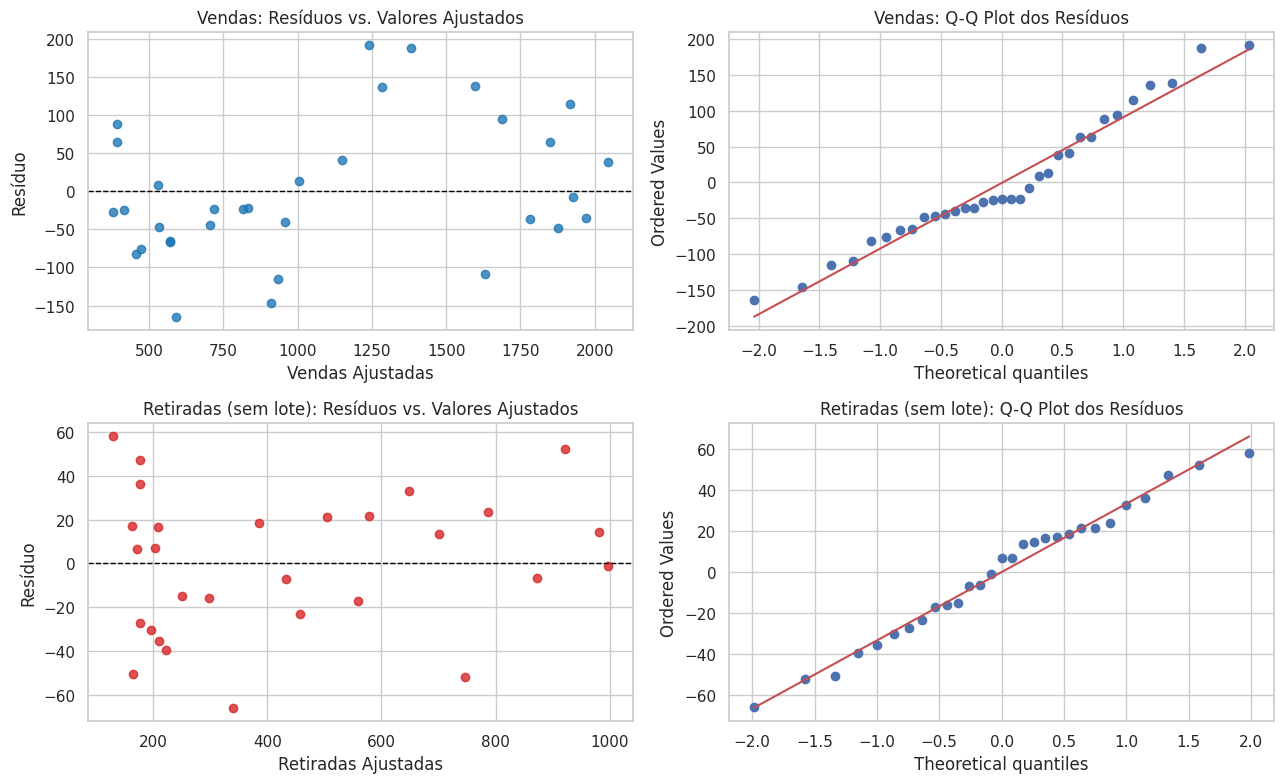

In [3]:
coef_v = pd.DataFrame(meta["champion_vendas"]["production_fit"]["coefficients"]["features"])
coef_r = pd.DataFrame(meta["champion_retiradas"]["production_fit"]["coefficients"]["features"])

print("=== COEFICIENTES — MODELO CAMPEÃO DE VENDAS ===")
display(coef_v)
print("Diagnóstico de Resíduos (Vendas):", meta["champion_vendas"]["production_fit"]["diagnostics"])

print("\n=== COEFICIENTES — MODELO CAMPEÃO DE RETIRADAS ===")
display(coef_r)
print("Diagnóstico de Resíduos (Retiradas):", meta["champion_retiradas"]["production_fit"]["diagnostics"])

# Gráficos de diagnóstico de resíduos
res_v = df_v_plot["vendas"] - df_v_plot["vendas_fit"]
df_r_clean = df_r_plot[df_r_plot["anomalia_retirada"] == 0]
res_r = df_r_clean["retiradas"] - df_r_clean["retiradas_fit"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].axhline(0, color="black", ls="--", lw=1)
axes[0, 0].scatter(df_v_plot["vendas_fit"], res_v, color="#1f77b4", alpha=0.8)
axes[0, 0].set_title("Vendas: Resíduos vs. Valores Ajustados")
axes[0, 0].set_xlabel("Vendas Ajustadas")
axes[0, 0].set_ylabel("Resíduo")

stats.probplot(res_v, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Vendas: Q-Q Plot dos Resíduos")

axes[1, 0].axhline(0, color="black", ls="--", lw=1)
axes[1, 0].scatter(df_r_clean["retiradas_fit"], res_r, color="#d62728", alpha=0.8)
axes[1, 0].set_title("Retiradas (sem lote): Resíduos vs. Valores Ajustados")
axes[1, 0].set_xlabel("Retiradas Ajustadas")
axes[1, 0].set_ylabel("Resíduo")

stats.probplot(res_r, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Retiradas (sem lote): Q-Q Plot dos Resíduos")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_diagnostico_residuos.png", dpi=140)
plt.show()
